## 1. Frozen specification

Fixed before any non-US result was computed; nothing below is changed after seeing results.

| Item | Value |
|---|---|
| Countries | OECD MEI monthly CPI (`<ISO>CPIALLMINMEI`, not seasonally adjusted): CAN GBR JPN DEU FRA ITA CHE SWE NOR DNK NLD BEL ESP AUT FIN PRT GRC KOR MEX ISL LUX TUR ISR ZAF. IRL excluded (missing and quarterly months). USA run with the same pipeline, reported separately, not pooled. |
| Target | YoY inflation higher h months later; primary h = 12, secondary h = 6 |
| Reference | LightGBM on: monthly π lags 0–12, ΔYoY lags 0–11, YoY, base effect, base-effect rule score |
| Test model | reference + RQA/RRc of seasonally adjusted monthly π: W = 120, m = 2, τ = 1, rr = 0.05, Euclidean on z, Theiler 1, RRc δ = 0.05, 19 IAAFT surrogates; columns DET, L, ENTR, LAM, DET3/DET2, K2, RR_last, RRc, dRRc; no window mean/std |
| Seasonal adjustment | causal: π_sa(t) = π(t) − mean over the 10 previous same-calendar months of (π − its trailing 12-month mean) |
| Classifier | same fixed LightGBM as all earlier notebooks; refit at the start of each test year on rows whose outcome is known |
| Test years | per country, from max(1990, first year with RP features + 10) to the last year with labels |
| Primary statistic | pooled gain = mean over the 24 countries of AUC(test) − AUC(reference) at h = 12; 95% interval from resampling calendar years jointly across countries (2,000 draws, seed 0) |
| Verdict | confirmed: interval above 0. Borderline: point estimate > 0, interval includes 0. Not confirmed: point estimate ≤ 0 |

## 2. Imports and shared code

In [1]:
import io
import sys
import time
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, accuracy_score

sys.path.insert(0, str(Path("../../src").resolve()))
from recplay.windowed import rqa_frame, rrc_frame, window_surrogates, euclidean_distance

COUNTRIES = ["CAN", "GBR", "JPN", "DEU", "FRA", "ITA", "CHE", "SWE", "NOR", "DNK", "NLD", "BEL", "ESP", "AUT",
             "FIN", "PRT", "GRC", "KOR", "MEX", "ISL", "LUX", "TUR", "ISR", "ZAF"]
ALL = ["USA"] + COUNTRIES
HORIZONS = [6, 12]
PRIMARY_H = 12
FIRST_TEST_YEAR = 1990
W, M, TAU, RR = 120, 2, 1, 0.05
THEILER, RRC_DELTA, N_SURR = 1, 0.05, 19
RQA_KEEP = ["DET", "L", "ENTR", "LAM", "DET3_DET2", "K2_lines", "RR_last"]
RP_COLS = [f"pi_{k}" for k in RQA_KEEP] + ["pi_RRc", "pi_dRRc"]

## 3. Data

CSV files are downloaded from FRED once into `data/raw/oecd_mei/`.

In [2]:
RAW_DIR = Path("../../data/raw/oecd_mei")


def load_cpi(iso: str) -> pd.Series:
    path = RAW_DIR / f"{iso}CPIALLMINMEI.csv"
    if not path.exists():
        RAW_DIR.mkdir(parents=True, exist_ok=True)
        url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={iso}CPIALLMINMEI"
        path.write_bytes(urllib.request.urlopen(url, timeout=60).read())
    df = pd.read_csv(path)
    s = pd.Series(pd.to_numeric(df.iloc[:, 1], errors="coerce").to_numpy(), index=pd.to_datetime(df.iloc[:, 0]))
    s = s.loc[s.first_valid_index():s.last_valid_index()].asfreq("MS")
    assert not s.isna().any(), f"{iso}: gap in monthly CPI"
    return s.rename(iso)


cpi = {iso: load_cpi(iso) for iso in ALL}
pd.DataFrame({iso: {"first": s.index[0].date(), "last": s.index[-1].date(), "months": len(s)} for iso, s in cpi.items()}).T

,first,last,months
USA,1955-01-01,2025-04-01,844
CAN,1914-01-01,2025-03-01,1335
GBR,1955-01-01,2025-03-01,843
JPN,1955-01-01,2021-06-01,798
DEU,1955-01-01,2025-03-01,843
FRA,1955-01-01,2025-03-01,843
ITA,1955-01-01,2025-03-01,843
CHE,1955-01-01,2025-04-01,844
SWE,1955-01-01,2025-03-01,843
NOR,1955-01-01,2025-04-01,844


## 4. Inflation, seasonal adjustment, targets and reference features

In [3]:
def seasonal_factor(pi: pd.Series, k: int) -> pd.Series:
    """At t, the seasonal factor of month t+k: mean of (π − trailing 12-month mean) over the 10 earlier same months."""
    dev = pi - pi.rolling(12).mean()
    return pd.concat([dev.shift(12 * j - k) for j in range(1, 11)], axis=1).mean(axis=1, skipna=False)


def base_effect(pi: pd.Series, h: int) -> pd.Series:
    """π_{t-11} + ... + π_{t-12+h}: the monthly inflation that leaves the YoY sum over the next h months."""
    return pi.rolling(h).sum().shift(12 - h)


def country_frame(s: pd.Series) -> pd.DataFrame:
    logp = np.log(s)
    pi = 100 * logp.diff()
    out = pd.DataFrame({"PI": pi, "YOY": 100 * (logp - logp.shift(12))})
    out["PI_SA"] = pi - seasonal_factor(pi, 0)
    for h in HORIZONS:
        future_season = sum(seasonal_factor(pi, k) for k in range(1, h + 1))
        out[f"rule_h{h}"] = h * out.PI_SA.rolling(3).mean() + future_season - base_effect(pi, h)
    return out


def targets(frame: pd.DataFrame, h: int) -> pd.Series:
    fut = frame.YOY.shift(-h)
    ok = fut.notna() & frame.YOY.notna()
    return (fut > frame.YOY)[ok].astype(int)


def reference_features(frame: pd.DataFrame, h: int, rule: bool = True) -> pd.DataFrame:
    pi, yoy = frame.PI, frame.YOY
    cols = {f"pi_lag{k}": pi.shift(k) for k in range(13)}
    cols |= {f"dyoy_lag{k}": yoy.diff().shift(k) for k in range(12)}
    cols |= {"yoy": yoy, "base_effect": base_effect(pi, h)}
    if rule:
        cols["rule"] = frame[f"rule_h{h}"]
    return pd.DataFrame(cols)


frames = {iso: country_frame(s) for iso, s in cpi.items()}

# YoY(t+h) - YoY(t) = (π_{t+1} + ... + π_{t+h}) - base effect, exactly
for iso, f in frames.items():
    for h in HORIZONS:
        gap = (f.YOY.shift(-h) - f.YOY) - (f.PI.rolling(h).sum().shift(-h) - base_effect(f.PI, h))
        assert gap.abs().max() < 1e-9, iso

# Seasonal adjustment check: spread of calendar-month means of π before and after, over 1990 on
season = pd.DataFrame({iso: {"raw": f.PI.loc["1990":].groupby(f.PI.loc["1990":].index.month).mean().std(),
                             "adjusted": f.PI_SA.loc["1990":].groupby(f.PI_SA.loc["1990":].index.month).mean().std()}
                       for iso, f in frames.items()}).T
season.round(3).T

,USA,CAN,GBR,JPN,DEU,FRA,ITA,CHE,SWE,NOR,...,FIN,PRT,GRC,KOR,MEX,ISL,LUX,TUR,ISR,ZAF
raw,0.196,0.187,0.261,0.214,0.174,0.190,0.096,0.176,0.255,0.237,...,0.165,0.33,1.077,0.265,0.247,0.158,0.458,0.786,0.248,0.205
adjusted,0.027,0.026,0.040,0.069,0.045,0.047,0.040,0.041,0.084,0.071,...,0.041,0.15,0.124,0.041,0.182,0.084,0.092,0.176,0.183,0.044


## 5. RP features

Delete `data/processed/crosscountry/` after changing feature code.

In [4]:
CACHE_DIR = Path("../../data/processed/crosscountry")
SERIES = {"pi": "PI_SA"}


def rp_features(frame: pd.DataFrame, iso: str) -> pd.DataFrame:
    data = frame[["PI_SA"]].dropna()
    rqa_df = rqa_frame(data, SERIES, {}, W, M, TAU, RR, euclidean_distance, THEILER)
    # ε comes from the target rate, so the RR of the whole window carries no information
    assert rqa_df["pi_RR"].std() < 1e-3
    surrogates = window_surrogates(data, SERIES, W, N_SURR)
    rrc_df = rrc_frame(data, SERIES, {}, W, M, TAU, euclidean_distance, surrogates, THEILER, RRC_DELTA)
    return rqa_df.join(rrc_df)[RP_COLS]


def load_rp(iso: str) -> pd.DataFrame:
    path = CACHE_DIR / f"{iso}.pkl"
    if path.exists():
        return pd.read_pickle(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    df = rp_features(frames[iso], iso)
    tmp = path.with_suffix(".tmp")
    df.to_pickle(tmp)
    tmp.replace(path)
    return df


t0 = time.perf_counter()
rp = dict(zip(ALL, Parallel(n_jobs=-1)(delayed(load_rp)(iso) for iso in ALL)))
first_test = {iso: max(FIRST_TEST_YEAR, rp[iso].index[0].year + 10) for iso in ALL}
print(f"RP features for {len(rp)} countries in {time.perf_counter() - t0:.0f} s")
pd.DataFrame({iso: {"first RP month": rp[iso].index[0].date(), "first test year": first_test[iso]} for iso in ALL}).T

RP features for 25 countries in 84 s


,first RP month,first test year
USA,1975-12-01,1990
CAN,1934-12-01,1990
GBR,1975-12-01,1990
JPN,1975-12-01,1990
DEU,1975-12-01,1990
FRA,1975-12-01,1990
ITA,1975-12-01,1990
CHE,1975-12-01,1990
SWE,1975-12-01,1990
NOR,1975-12-01,1990


## 6. Leakage check

In [5]:
iso = "DEU"
for month in ["1995-01-01", "2010-06-01", "2020-04-01"]:
    trunc_frame = country_frame(cpi[iso].loc[:month])
    trunc_rp = rp_features(trunc_frame, iso)
    assert np.allclose(rp[iso].loc[month], trunc_rp.loc[month], equal_nan=True), month
    for h in HORIZONS:
        a = reference_features(frames[iso], h).loc[month]
        b = reference_features(trunc_frame, h).loc[month]
        assert np.allclose(a, b, equal_nan=True), (month, h)
print("features at t use only data up to t")

features at t use only data up to t


## 7. Walk-forward fits

In [6]:
def make_classifier():
    return LGBMClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, num_leaves=7, min_child_samples=20,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=0, n_jobs=1, verbose=-1)


def walk_forward(X: pd.DataFrame, y: pd.Series, h: int, first_year: int) -> pd.Series:
    """Refit at the start of each year Y on rows whose outcome month t+h is not after Y-01; predict year Y."""
    X = X.reindex(y.index)
    pred = pd.Series(np.nan, index=y.index)
    for year in range(first_year, y.index.year.max() + 1):
        start = pd.Timestamp(year, 1, 1)
        train = y.index.shift(h, freq="MS") <= start
        test = y.index.year == year
        if not test.any():
            continue
        assert y.index[train].max() + pd.DateOffset(months=h) <= start <= y.index[test].min()
        pred[test] = make_classifier().fit(X[train], y[train]).predict_proba(X[test])[:, 1]
    return pred.dropna()


MODELS = {"reference": lambda iso, h: reference_features(frames[iso], h),
          "reference without rule": lambda iso, h: reference_features(frames[iso], h, rule=False),
          "reference + RP": lambda iso, h: reference_features(frames[iso], h).join(rp[iso])}

t0 = time.perf_counter()
jobs = [(iso, h, name) for iso in ALL for h in HORIZONS for name in MODELS]
preds = dict(zip(jobs, Parallel(n_jobs=-1)(
    delayed(walk_forward)(MODELS[name](iso, h), targets(frames[iso], h), h, first_test[iso]) for iso, h, name in jobs)))
print(f"{len(jobs)} walk-forward runs in {time.perf_counter() - t0:.0f} s")

150 walk-forward runs in 34 s


## 8. Results per country

In [7]:
rows = []
for iso in ALL:
    for h in HORIZONS:
        y = targets(frames[iso], h)
        p = {name: preds[iso, h, name] for name in MODELS}
        idx = p["reference"].index
        t = y[idx]
        row = {"country": iso, "h": h, "first year": first_test[iso], "last year": idx.year.max(), "n": len(idx),
               "up share": t.mean()}
        row |= {f"{name} AUC": roc_auc_score(t, p[name][idx]) for name in MODELS}
        row["gain"] = row["reference + RP AUC"] - row["reference AUC"]
        row["rule effect"] = row["reference AUC"] - row["reference without rule AUC"]
        row["reference acc"] = accuracy_score(t, p["reference"][idx] >= 0.5)
        row["reference + RP acc"] = accuracy_score(t, p["reference + RP"][idx] >= 0.5)
        rows.append(row)
by_country = pd.DataFrame(rows).set_index(["h", "country"]).sort_index()
by_country.round(3)

first year  last year    n  up share  reference AUC  \
h  country                                                        
6  AUT            1990       2024  417     0.456          0.643   
   BEL            1990       2024  418     0.483          0.730   
   CAN            1990       2024  417     0.501          0.707   
   CHE            1990       2024  418     0.476          0.695   
   DEU            1990       2024  417     0.465          0.674   
   DNK            1997       2024  334     0.509          0.681   
   ESP            1990       2024  417     0.465          0.694   
   FIN            1990       2024  417     0.468          0.807   
   FRA            1990       2024  417     0.482          0.626   
   GBR            1990       2024  417     0.429          0.706   
   GRC            1990       2024  418     0.421          0.648   
   ISL            1990       2024  418     0.498          0.776   
   ISR            2000       2024  297     0.512          0.642   
   ITA            1990       2024  417     0.448          0.742   
   JPN            1990       2020  372     0.478          0.689   
   KOR            1990       2023  401     0.491          0.688   
   LUX            1990       2024  418     0.459          0.717   
   MEX            1999       2024  301     0.458          0.680   
   NLD            1991       2024  406     0.500          0.677   
   NOR            1990       2024  418     0.481          0.660   
   PRT            1990       2024  418     0.452          0.658   
   SWE            1990       2024  417     0.489          0.692   
   TUR            1990       2024  418     0.488          0.713   
   USA            1990       2024  418     0.517          0.685   
   ZAF            1990       2024  415     0.506          0.727   
12 AUT            1990       2024  411     0.426          0.571   
   BEL            1990       2024  412     0.490          0.686   
   CAN            1990       2024  411     0.491          0.669   
   CHE            1990       2024  412     0.447          0.657   
   DEU            1990       2024  411     0.479          0.720   
   DNK            1997       2024  328     0.466          0.619   
   ESP            1990       2024  411     0.462          0.651   
   FIN            1990       2024  411     0.455          0.684   
   FRA            1990       2024  411     0.457          0.552   
   GBR            1990       2024  411     0.418          0.678   
   GRC            1990       2024  412     0.364          0.663   
   ISL            1990       2024  412     0.468          0.651   
   ISR            2000       2024  291     0.495          0.606   
   ITA            1990       2024  411     0.433          0.628   
   JPN            1990       2020  366     0.464          0.570   
   KOR            1990       2022  395     0.481          0.562   
   LUX            1990       2024  412     0.466          0.682   
   MEX            1999       2023  295     0.417          0.736   
   NLD            1991       2024  400     0.518          0.629   
   NOR            1990       2024  412     0.485          0.670   
   PRT            1990       2024  412     0.408          0.693   
   SWE            1990       2024  411     0.506          0.600   
   TUR            1990       2024  412     0.498          0.612   
   USA            1990       2024  412     0.483          0.690   
   ZAF            1990       2024  409     0.491          0.709   

            reference without rule AUC  reference + RP AUC   gain  \
h  country                                                          
6  AUT                           0.645               0.593 -0.050   
   BEL                           0.745               0.729 -0.001   
   CAN                           0.684               0.730  0.023   
   CHE                           0.686               0.638 -0.057   
   DEU                           0.704               0.648 -0.026   
   DNK                           0.675      

## 9. Pooled test

In [8]:
def pooled_gain(h, countries, n=2000):
    """Mean over countries of AUC(test) − AUC(reference); interval from resampling calendar years jointly."""
    data = {}
    for iso in countries:
        idx = preds[iso, h, "reference"].index
        data[iso] = (targets(frames[iso], h)[idx].to_numpy(), preds[iso, h, "reference + RP"][idx].to_numpy(),
                     preds[iso, h, "reference"][idx].to_numpy(), idx.year.to_numpy())
    years = np.unique(np.concatenate([d[3] for d in data.values()]))
    groups = {iso: {yr: np.flatnonzero(d[3] == yr) for yr in years} for iso, d in data.items()}

    def stat(draw):
        gains = []
        for iso, (t, pt, pr, _) in data.items():
            i = np.concatenate([groups[iso][yr] for yr in draw])
            if len(np.unique(t[i])) < 2:
                continue
            gains.append(roc_auc_score(t[i], pt[i]) - roc_auc_score(t[i], pr[i]))
        return np.mean(gains)

    rng = np.random.default_rng(0)
    point = stat(years)
    boot = [stat(rng.choice(years, len(years))) for _ in range(n)]
    return point, *np.quantile(boot, [0.025, 0.975])


rows = []
for h in HORIZONS:
    g, lo, hi = pooled_gain(h, COUNTRIES)
    gains = by_country.loc[h].loc[COUNTRIES, "gain"]
    rows.append({"h": h, "pooled gain": g, "lo": lo, "hi": hi, "countries with gain > 0": int((gains > 0).sum()),
                 "countries": len(gains), "median gain": gains.median(),
                 "mean rule effect": by_country.loc[h].loc[COUNTRIES, "rule effect"].mean()})
pooled = pd.DataFrame(rows).set_index("h")

g, lo, hi = pooled.loc[PRIMARY_H, ["pooled gain", "lo", "hi"]]
verdict = "confirmed" if lo > 0 else ("borderline" if g > 0 else "not confirmed")
print(f"Primary (h = {PRIMARY_H}): pooled gain {g:+.4f} (95% {lo:+.4f} to {hi:+.4f}) -> {verdict}")
pooled.round(4)

Primary (h = 12): pooled gain -0.0331 (95% -0.0585 to -0.0081) -> not confirmed


,pooled gain,lo,hi,countries with gain > 0,countries,median gain,mean rule effect
h,,,,,,,
6,-0.0310,-0.0432,-0.0186,4,24,-0.0291,0.0123
12,-0.0331,-0.0585,-0.0081,7,24,-0.0291,0.0027


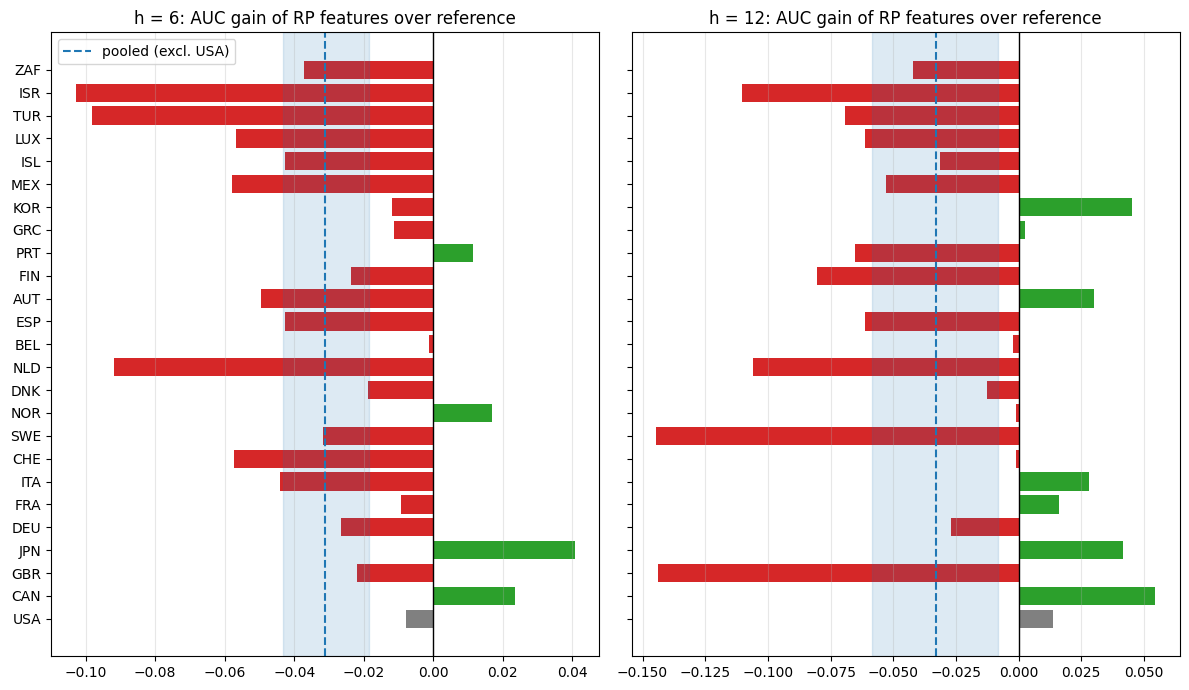

In [9]:
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(12, 7), sharey=True)
for ax, h in zip(axes, HORIZONS):
    d = by_country.loc[h].loc[ALL]
    ax.barh(range(len(d)), d.gain, color=["grey" if iso == "USA" else ("tab:green" if v > 0 else "tab:red")
                                         for iso, v in d.gain.items()])
    ax.axvline(0, color="black", lw=1)
    ax.axvline(pooled.loc[h, "pooled gain"], color="tab:blue", ls="--", label="pooled (excl. USA)")
    ax.axvspan(pooled.loc[h, "lo"], pooled.loc[h, "hi"], color="tab:blue", alpha=0.15)
    ax.set_yticks(range(len(d)), d.index)
    ax.set_title(f"h = {h}: AUC gain of RP features over reference")
    ax.grid(alpha=0.3, axis="x")
axes[0].legend()
fig.tight_layout()
plt.show()